# 🚀 Practice Day 53

**📅 Date:** **2026-11-04**  
**📁 Category:** **Phase 3 · SQL 고급(윈도우함수) (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice window functions in DuckDB — PARTITION BY, a moving average, LAG, and RANK — to analyze multiple YouTube channels over time
  (DuckDB 윈도우 함수 연습 — PARTITION BY, 이동평균, LAG, RANK로 여러 채널의 시계열 데이터 분석하기)
- Smooth out daily noise to see each channel's real trend, catch a viral spike as it happens, and see how channel rankings shift day to day
  (일별 노이즈를 걷어내고 채널별 실제 추세를 보고, 급상승 구간을 포착하고, 채널 순위가 날마다 어떻게 바뀌는지 확인하기)

---
# 📂 Dataset

**Dataset Name:** 5-Channel Daily YouTube Views / 5개 유튜브 채널 일별 조회수 데이터

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 90 days of daily views across 5 channels (PixelForge, DailyByte, GreenThumb Living, UrbanBeats, MindSpark) — 450 rows total (5 channels × 90 days), single table. Each channel has its own growth trend and volatility, and UrbanBeats has one clear viral spike partway through the period. Clean — no missing values or duplicates. The focus is applying window functions per channel (PARTITION BY).
(5개 채널(PixelForge/DailyByte/GreenThumb Living/UrbanBeats/MindSpark)의 90일간 일별 조회수 데이터입니다(단일 테이블, 450행 = 5채널×90일). 채널마다 고유한 성장 추세와 변동성을 가지며, UrbanBeats는 기간 중반에 뚜렷한 급상승(바이럴) 구간이 있습니다. 결측치·중복 없이 깨끗합니다. 채널(PARTITION) 단위로 윈도우 함수를 적용하는 데 초점을 둡니다.)

## Dataset Preview

In [17]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate daily views for 5 YouTube channels over 90 days ---
channels = ['PixelForge', 'DailyByte', 'GreenThumb Living', 'UrbanBeats', 'MindSpark']
base_views = {'PixelForge': 18000, 'DailyByte': 22000, 'GreenThumb Living': 6000, 'UrbanBeats': 9000, 'MindSpark': 12000}
daily_growth = {'PixelForge': 0.006, 'DailyByte': 0.001, 'GreenThumb Living': 0.004, 'UrbanBeats': 0.0, 'MindSpark': 0.002}
daily_vol = {'PixelForge': 0.10, 'DailyByte': 0.18, 'GreenThumb Living': 0.09, 'UrbanBeats': 0.15, 'MindSpark': 0.08}

n_days = 90
dates = pd.date_range('2024-01-01', periods=n_days, freq='D')

rows = []
for ch in channels:
    for i, d in enumerate(dates):
        growth_mult = (1 + daily_growth[ch]) ** i
        noise = rng.normal(1.0, daily_vol[ch])
        v = base_views[ch] * growth_mult * noise
        # UrbanBeats gets one viral spike around day 40, decaying back down over ~2 weeks
        if ch == 'UrbanBeats':
            spike_center = 40
            if abs(i - spike_center) < 14:
                decay = np.exp(-((i - spike_center) ** 2) / (2 * 5.0 ** 2))
                v = v + base_views[ch] * 12 * decay
        v = max(500, v)
        rows.append({'date': d, 'channel': ch, 'daily_views': int(round(v))})

df = pd.DataFrame(rows).sort_values(['channel', 'date']).reset_index(drop=True)

df.head(10)


,date,channel,daily_views
0,2024-01-01,DailyByte,24635
1,2024-01-02,DailyByte,21632
2,2024-01-03,DailyByte,20364
3,2024-01-04,DailyByte,21749
4,2024-01-05,DailyByte,15380
5,2024-01-06,DailyByte,16351
6,2024-01-07,DailyByte,16863
7,2024-01-08,DailyByte,18178
8,2024-01-09,DailyByte,23772
9,2024-01-10,DailyByte,18581


## Dataset Information

In [18]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         450 non-null    datetime64[us]
 1   channel      450 non-null    str           
 2   daily_views  450 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 10.7 KB

Shape: (450, 3)


,date,channel,daily_views
count,450,450,450.000000
unique,NaN,5,NaN
top,NaN,DailyByte,NaN
freq,NaN,90,NaN
mean,2024-02-14 12:00:00,NaN,18122.373333
min,2024-01-01 00:00:00,NaN,5385.000000
25%,2024-01-23 00:00:00,NaN,9050.750000
50%,2024-02-14 12:00:00,NaN,13883.500000
75%,2024-03-08 00:00:00,NaN,22988.250000
max,2024-03-30 00:00:00,NaN,118590.000000


---
# ❓ Business Questions

1. **(Analysis)** What is each channel's 7-day moving average daily views, and how does it smooth out the daily noise (and any spikes)?  
   (채널별 7일 이동평균 조회수는 어떻게 되며, 일별 노이즈(및 급상승 구간)를 어떻게 완화하는가?)
2. **(Analysis)** What is each channel's day-over-day percentage change in views, and which single day saw the biggest swing?  
   (채널별 전일 대비 조회수 증감률은 얼마이며, 가장 큰 변동을 보인 날은 언제인가?)
3. **(Analysis)** On any given day, how do the 5 channels rank against each other by views, and does that ranking ever change?  
   (특정 날짜 기준으로 5개 채널의 조회수 순위는 어떻게 되며, 그 순위가 바뀌는 경우가 있는가?)
4. **(Visualization)** Show how each channel's smoothed (moving average) view trend moves over the 90 days.  
   (채널별 이동평균 조회수 추이는 90일간 어떻게 움직이는가?)
5. **(Visualization)** Compare total views across all 5 channels over the full period.  
   (전체 기간 5개 채널의 총조회수를 비교하면?)

---
# 🔍 Data Cleaning Check


In [19]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
date           0
channel        0
daily_views    0
dtype: int64

Duplicate rows: 0

Dtypes
date           datetime64[us]
channel                   str
daily_views             int64
dtype: object

Column names
['date', 'channel', 'daily_views']

Text columns — unique counts
channel    5
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** What is each channel's 7-day moving average daily views, and how does it smooth out the daily noise? (채널별 7일 이동평균 조회수는? 노이즈를 어떻게 완화하는가?)

**Result:** On 2024-01-05, DailyByte has **15,380** views and a 7-day average of **20,752**. The day before, views are **21,749** and the average is **22,095**.  
(2024-01-05 DailyByte 조회수는 15,380, 7일 평균은 20,752. 전날 조회수는 21,749, 평균은 22,095)

**Insight:** Views fall by **6,369**, while the average falls by **1,343**. On 2024-01-01 the average equals that day's views, **24,635**.  
(조회수는 6,369 줄고, 평균은 1,343 줄음. 2024-01-01에는 평균이 그날 조회수 24,635와 같음)

In [20]:
# Question 1 (DuckDB, window function): 7-day moving average daily views per channel
import duckdb

seven_day_ma = duckdb.sql("""
    SELECT
        channel,
        date,
        daily_views,
        AVG(daily_views) OVER (
            PARTITION BY channel ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS ma7
    FROM df
    ORDER BY channel, date
""").df()

seven_day_ma

,channel,date,daily_views,ma7
0,DailyByte,2024-01-01,24635,24635.000000
1,DailyByte,2024-01-02,21632,23133.500000
2,DailyByte,2024-01-03,20364,22210.333333
3,DailyByte,2024-01-04,21749,22095.000000
4,DailyByte,2024-01-05,15380,20752.000000
...,...,...,...,...
445,UrbanBeats,2024-03-26,9314,9816.714286
446,UrbanBeats,2024-03-27,9316,9577.142857
447,UrbanBeats,2024-03-28,9365,9558.285714
448,UrbanBeats,2024-03-29,7834,9228.428571


## Question 2

**Question:** What is each channel's day-over-day percentage change in views, and which single day saw the biggest swing? (전일 대비 증감률은? 가장 큰 변동을 보인 날은?)

**Result:** The biggest swing is DailyByte on 2024-02-23, at **70.27%**. UrbanBeats on 2024-03-20 is next at **60.13%**. The gap is **10.14** percentage points.  
(가장 큰 변동은 2024-02-23 DailyByte 70.27%. 다음은 2024-03-20 UrbanBeats 60.13%. 차이는 10.14%p)

**Insight:** The next printed swings are UrbanBeats on 2024-03-12 at **59.32%**, DailyByte on 2024-03-13 at **59.24%**, and UrbanBeats on 2024-01-25 at **56.82%**. Each channel's first day has no prior day.  
(그다음은 2024-03-12 UrbanBeats 59.32%, 2024-03-13 DailyByte 59.24%, 2024-01-25 UrbanBeats 56.82%. 각 채널의 첫날은 전일이 없음)

In [21]:
# Question 2 (DuckDB, window function): day-over-day % change per channel using LAG

day_over_day_pct_change = duckdb.sql("""
    SELECT
        channel,
        date,
        daily_views,
        (daily_views - LAG(daily_views) OVER (
            PARTITION BY channel ORDER BY date
        )) / LAG(daily_views) OVER (PARTITION BY channel ORDER BY date) * 100 AS pct_change
    FROM df
    ORDER BY ABS(pct_change) DESC
""").df()

day_over_day_pct_change

,channel,date,daily_views,pct_change
0,DailyByte,2024-02-23,24315,70.273109
1,UrbanBeats,2024-03-20,10993,60.131100
2,UrbanBeats,2024-03-12,9411,59.319451
3,DailyByte,2024-03-13,32699,59.235452
4,UrbanBeats,2024-01-25,8680,56.820235
...,...,...,...,...
445,PixelForge,2024-01-01,18548,NaN
446,DailyByte,2024-01-01,24635,NaN
447,UrbanBeats,2024-01-01,8026,NaN
448,GreenThumb Living,2024-01-01,6705,NaN


## Question 3

**Question:** On any given day, how do the 5 channels rank against each other by views, and does that ranking ever change? (특정 날짜 기준 5개 채널의 순위는? 순위가 바뀌는가?)

**Result:** On 2024-01-01, DailyByte ranks **1st** with **24,635** views and PixelForge ranks **2nd** with **18,548**. On 2024-03-30, PixelForge ranks **1st** with **32,023** and DailyByte ranks **2nd** with **25,284**.  
(2024-01-01 1위는 DailyByte 24,635, 2위는 PixelForge 18,548. 2024-03-30 1위는 PixelForge 32,023, 2위는 DailyByte 25,284)

**Insight:** The top-two gap is **6,087** on 2024-01-01 and **6,739** on 2024-03-30. MindSpark stays **3rd**, UrbanBeats **4th**, and GreenThumb Living **5th** on both printed days.  
(1·2위 차이는 2024-01-01에 6,087, 2024-03-30에 6,739. 출력된 두 날 모두 MindSpark 3위, UrbanBeats 4위, GreenThumb Living 5위)

In [22]:
# Question 3 (DuckDB, window function): daily rank of channels by views
daily_rank = duckdb.sql("""
    SELECT
        channel,
        date,
        daily_views,
        RANK() OVER (
            PARTITION BY date ORDER BY daily_views DESC
        ) AS rank
    FROM df
    ORDER BY date, rank
""").df()

daily_rank


,channel,date,daily_views,rank
0,DailyByte,2024-01-01,24635,1
1,PixelForge,2024-01-01,18548,2
2,MindSpark,2024-01-01,11854,3
3,UrbanBeats,2024-01-01,8026,4
4,GreenThumb Living,2024-01-01,6705,5
...,...,...,...,...
445,PixelForge,2024-03-30,32023,1
446,DailyByte,2024-03-30,25284,2
447,MindSpark,2024-03-30,14775,3
448,UrbanBeats,2024-03-30,8801,4


---
# 📈 Visualization

**Chart 1:** Line chart — 7-day moving average views trend by channel (선그래프: 채널별 7일 이동평균 조회수 추이)

*Interpretation:* The lines are the 7-day averages. On 2024-01-05, DailyByte's average is **20,752** while that day's views are **15,380**.  
(선은 7일 평균. 2024-01-05 DailyByte 평균은 20,752, 그날 조회수는 15,380)

---

**Chart 2:** Bar chart — total views by channel (막대그래프: 채널별 총조회수)

*Interpretation:* UrbanBeats has **2,164,882** views. PixelForge has **2,140,559**, DailyByte **2,025,786**, MindSpark **1,176,357**, and GreenThumb Living **647,484**.  
(UrbanBeats 2,164,882. PixelForge 2,140,559, DailyByte 2,025,786, MindSpark 1,176,357, GreenThumb Living 647,484)

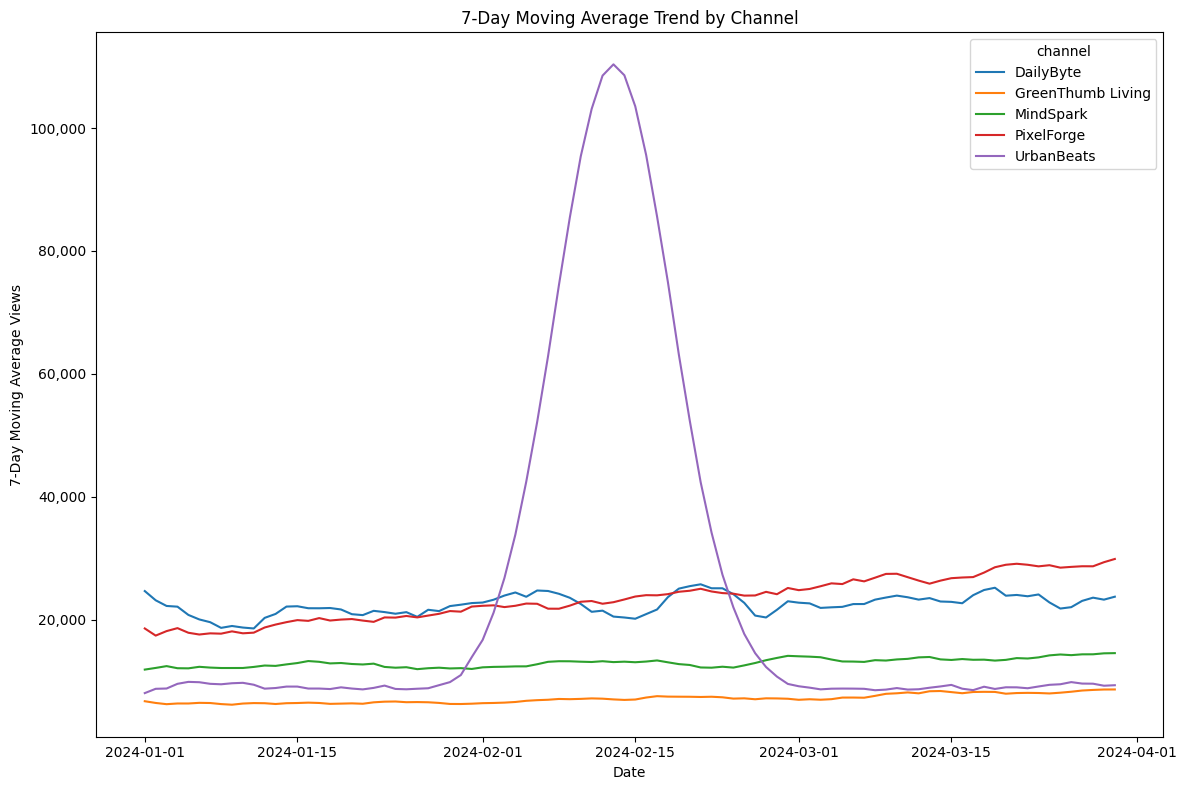

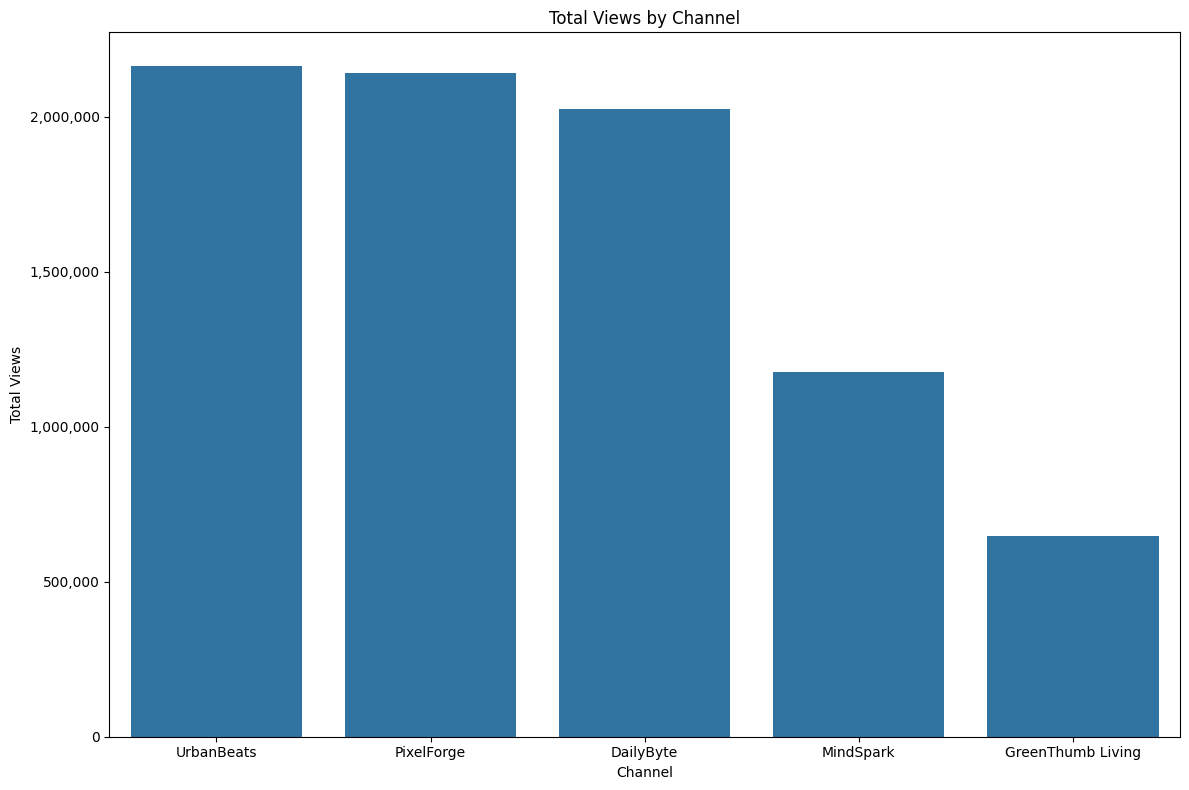

In [25]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: 7-day moving average trend per channel (reuse the ma7 column from Question 1)
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(data=seven_day_ma, x='date', y='ma7', hue='channel', ax=ax)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set_title('7-Day Moving Average Trend by Channel')
ax.set_xlabel('Date')
ax.set_ylabel('7-Day Moving Average Views')
plt.tight_layout()
plt.show()

# Chart 2: total views by channel over the full period (bar)
total_views = df.groupby('channel')['daily_views'].sum().sort_values(ascending=False).reset_index()

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(x='channel', y='daily_views', data=total_views, order=total_views['channel'], errorbar=None, ax=ax, estimator=sum)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set_title('Total Views by Channel')
ax.set_xlabel('Channel')
ax.set_ylabel('Total Views')
plt.tight_layout()

---
# 💼 Business Insights
*What did I discover?*

- DailyByte views fall by **6,369** on 2024-01-05, while the 7-day average falls by **1,343**.  
  (2024-01-05 DailyByte 조회수는 6,369 줄고, 7일 평균은 1,343 줄음)
- The biggest day-over-day swing is DailyByte on 2024-02-23, at **70.27%**.  
  (전일 대비 가장 큰 변동은 2024-02-23 DailyByte 70.27%)
- Rank 1 changes from DailyByte on 2024-01-01 to PixelForge on 2024-03-30.  
  (1위는 2024-01-01 DailyByte에서 2024-03-30 PixelForge로 바뀜)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. UrbanBeats leads the period with **2,164,882** views, **24,323** above PixelForge.  
   (기간 합계 1위는 UrbanBeats 2,164,882로 PixelForge보다 24,323 많음)
2. Read the 7-day average next to a large day. DailyByte's **70.27%** swing is one day, while the printed average drop is **1,343** views.  
   (큰 하루 옆에는 7일 평균을 같이 볼 것. DailyByte 70.27%는 하루이고, 출력된 평균 감소는 1,343)
3. Do not keep the 2024-01-01 ranking. PixelForge is **1st** on 2024-03-30 with **32,023** views.  
   (2024-01-01 순위를 유지하지 않기. 2024-03-30 1위는 PixelForge 32,023)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- The saved queries and both charts ran as written.  
  (저장한 쿼리와 차트 둘은 쓴 그대로 실행됨)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `AVG() OVER (PARTITION BY channel ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)` is the 7-day average.  
  (`AVG() OVER (PARTITION BY channel ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)`가 7일 평균)
- A day-over-day percent is `(daily_views - LAG(daily_views)) / LAG(daily_views) * 100` inside the same channel.  
  (전일 대비 비율은 같은 채널 안에서 `(daily_views - LAG(daily_views)) / LAG(daily_views) * 100`)
- `RANK() OVER (PARTITION BY date ORDER BY daily_views DESC)` ranks the five channels on one day.  
  (`RANK() OVER (PARTITION BY date ORDER BY daily_views DESC)`가 하루의 채널 다섯 순위를 만듦)  

---
# 🧠 Reflection

**What was difficult?**  
Nothing in the three queries needed a change.  
(쿼리 세 개는 고칠 곳이 없었음)

**Why?**  
The moving average, the prior-day percent, and the daily rank each use one window.  
(이동평균, 전일 비율, 일별 순위가 각각 윈도우 하나를 씀)

**How did I solve it?**  
Kept `PARTITION BY channel` for the time windows and `PARTITION BY date` for the rank.  
(시간 윈도우는 `PARTITION BY channel`, 순위는 `PARTITION BY date`로 둠)

**What would I do differently next time?**  
Read the first day of a window, where the average still equals that day's views.  
(윈도우의 첫날은 평균이 그날 조회수와 같은지 확인하기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
DailyByte's 2024-01-05 average is **20,752** against **15,380** views. The largest swing is **70.27%**, and rank 1 changes by 2024-03-30.  
(2024-01-05 DailyByte 평균은 20,752, 조회수는 15,380. 가장 큰 변동은 70.27%이고, 1위는 2024-03-30에 바뀜)

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  
Each question used one window function. The tables were enough to compare a day with its average.  
(질문마다 윈도우 함수 하나를 씀. 표만으로 하루와 평균을 비교할 수 있었음)

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 54 — end-to-end mini pipeline (Round 4/5)  
  (정제부터 집계와 차트까지 한 데이터로 이어 풀기)  